# KAN-7 — Agregações do histórico de pedidos

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

Objetivo: transformar a tabela de pedidos (uma linha por pedido) em uma tabela de **features comportamentais por cliente**, indexada por `id_cliente`, para o modelo comportamental (KAN-8).

O código fica em `src/features_comportamentais.py`. Este notebook mostra as decisões, confere o resultado e mede o risco de **vazamento temporal**: os dados não têm data de referência, e o último pedido de cada cliente pode ser aquele em que a inadimplência foi observada. Por isso geramos duas versões:
- **(a) todos os pedidos**;
- **(b) sem o último pedido** (conservadora).

> Os CSVs ficam em `data/raw/` e **não vão para o GitHub** (termo de confidencialidade da Praso). Aqui mostramos só agregados, nunca linhas de clientes.

> Os cruzamentos com o alvo neste notebook são exploratórios (base inteira). A avaliação de verdade é na KAN-8, com o split salvo pela KAN-6.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

from src import dados
from src import features_comportamentais as fc

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Carregamento e conversão das faixas

In [2]:
clientes, pedidos = dados.carregar_dados_limpos()
pedidos = fc.converter_pedidos(pedidos)
print("clientes:", clientes.shape, "| pedidos válidos:", pedidos.shape)
print("clientes com pedidos: {} ({:.1%})".format(pedidos["id_cliente"].nunique(), pedidos["id_cliente"].nunique() / len(clientes)))

clientes: (3000, 19) | pedidos válidos: (1975, 11)
clientes com pedidos: 664 (22.1%)


In [3]:
# Como cada faixa virou número (ponto médio; sem atraso = 0; faixa aberta = limite inferior)
for col in ["valor", "atraso"]:
    t = pedidos.groupby(col).agg(num=(f"{col}_num", "first"), ord=(f"{col}_ord", "first"), pedidos=(col, "size"))
    print(t.sort_values("ord").assign(pct=lambda d: (d.pedidos / d.pedidos.sum()).round(3)), "\n")

                     num  ord  pedidos    pct
valor                                        
(0, 500]           250.0    0     1577  0.798
(500, 1000]        750.0    1      277  0.140
(1000, 2000]      1500.0    2       97  0.049
(2000, 10000000]  2000.0    3       24  0.012 

                 num  ord  pedidos    pct
atraso                                   
(-100, 0]        0.0    0      542  0.274
(0, 2]           1.0    1      903  0.457
(2, 4]           3.0    2      255  0.129
(4, 6]           5.0    3      105  0.053
(6, 10]          8.0    4       74  0.037
(10, 15]        12.5    5       40  0.020
(15, 30]        22.5    6       28  0.014
(30, 60]        45.0    7       16  0.008
(60, 10000000]  60.0    8       12  0.006 



## 2. Estrutura do histórico

Antes de agregar, vale entender o que existe por cliente.

In [4]:
por_cliente = pedidos.groupby("id_cliente").size()
print("pedidos por cliente:", por_cliente.value_counts().sort_index().to_dict())
intervalo = fc.ordenar_pedidos(pedidos).groupby("id_cliente")["data_entrega"].diff().dt.days.dropna()
print("dias entre pedidos consecutivos:", intervalo.describe().round(1).to_dict())
print("pares de pedidos no mesmo dia:", int((intervalo == 0).sum()))

pedidos por cliente: {1: 2, 2: 13, 3: 649}
dias entre pedidos consecutivos: {'count': 1311.0, 'mean': 55.3, 'std': 118.9, 'min': 0.0, '25%': 8.0, '50%': 15.0, '75%': 33.0, 'max': 1314.0}
pares de pedidos no mesmo dia: 74


Quase todo cliente tem **exatamente 3 pedidos**: parece um recorte com os últimos 3 pedidos, não o histórico completo. Então `n_pedidos` quase não varia e o "volume de compras" não é observável. As features úteis descrevem **como** foram esses 3 pedidos (valor, atraso, ritmo).

### Sinal por posição do pedido

Se o último pedido for o que gerou a inadimplência, o atraso dele deve separar o alvo muito mais do que o dos anteriores.

In [5]:
alvo = clientes.set_index("id_cliente")["inadimplente"]
ordenados = fc.ordenar_pedidos(pedidos)
ordenados["posicao"] = ordenados.groupby("id_cliente").cumcount(ascending=False).map({0: "último", 1: "penúltimo", 2: "antepenúltimo"})
ordenados = ordenados.join(alvo, on="id_cliente")
posicao = (ordenados.dropna(subset=["posicao"])
           .groupby(["posicao", "atrasou_2d"])["inadimplente"].agg(["size", "mean"]).round(3))
posicao

size   mean
posicao       atrasou_2d             
antepenúltimo 0            497  0.167
              1            152  0.289
penúltimo     0            477  0.155
              1            185  0.335
último        0            471  0.136
              1            193  0.383

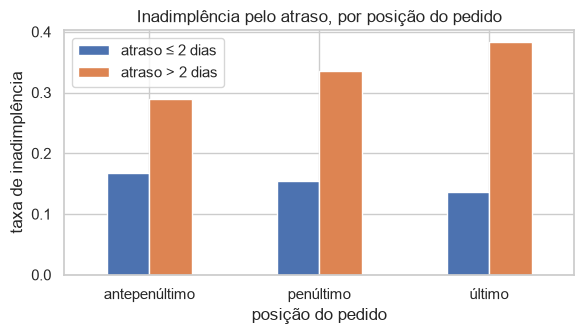

In [6]:
tab = posicao["mean"].unstack().loc[["antepenúltimo", "penúltimo", "último"]]
tab.columns = ["atraso ≤ 2 dias", "atraso > 2 dias"]
ax = tab.plot.bar(figsize=(6, 3.5), rot=0, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("taxa de inadimplência"); ax.set_xlabel("posição do pedido")
ax.set_title("Inadimplência pelo atraso, por posição do pedido")
plt.tight_layout(); plt.savefig(FIG / "kan7_atraso_por_posicao.png", dpi=150); plt.show()

### Sinal pela época do último pedido

Recência absoluta (dias até uma data fixa) mediria a época em que o cliente comprou. Se a taxa varia muito com a época, a recência capturaria isso, e não o comportamento.

           size   mean
trimestre             
2023Q1       40  0.075
2023Q2      120  0.250
2023Q3      149  0.302
2023Q4      140  0.221
2024Q1       76  0.158
2024Q2       55  0.109
2024Q3       30  0.067


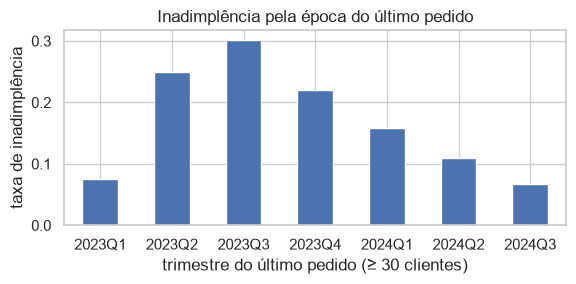

In [7]:
ultimo = ordenados.groupby("id_cliente")["data_entrega"].max()
epoca = pd.concat([ultimo.dt.to_period("Q").rename("trimestre"), alvo], axis=1, join="inner")
por_epoca = epoca.groupby("trimestre")["inadimplente"].agg(["size", "mean"]).round(3)
por_epoca_relevante = por_epoca[por_epoca["size"] >= 30]
print(por_epoca_relevante)
ax = por_epoca_relevante["mean"].plot.bar(figsize=(6, 3), rot=0, color="#4C72B0")
ax.set_ylabel("taxa de inadimplência"); ax.set_xlabel("trimestre do último pedido (≥ 30 clientes)")
ax.set_title("Inadimplência pela época do último pedido")
plt.tight_layout(); plt.savefig(FIG / "kan7_taxa_por_epoca.png", dpi=150); plt.show()

## 3. Agregação por cliente

As features estão em `fc.DICIONARIO`. Nada usa o alvo nem estatísticas da base inteira, então podem ser calculadas antes do split. Nulos ficam nulos (imputar é decisão da KAN-8, dentro do `Pipeline`).

In [8]:
todos = fc.agregar_pedidos(pedidos)
sem_ultimo = fc.agregar_pedidos(pedidos, excluir_ultimo=True)
print("(a) todos os pedidos:", todos.shape, "| (b) sem o último:", sem_ultimo.shape)
assert todos.index.is_unique and sem_ultimo.index.is_unique
assert (sem_ultimo["n_pedidos"] == todos.loc[sem_ultimo.index, "n_pedidos"] - 1).all()
pd.DataFrame({"nulos (a)": todos.isna().sum(), "nulos (b)": sem_ultimo.isna().sum()})

(a) todos os pedidos: (664, 14) | (b) sem o último: (662, 14)


,nulos (a),nulos (b)
n_pedidos,0,0
valor_media,0,0
valor_min,0,0
valor_max,0,0
valor_ord_max,0,0
atraso_media,0,0
atraso_max,0,0
atraso_ord_max,0,0
pct_atraso,0,0
pct_atraso_2d,0,0


In [9]:
todos.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_pedidos,664.0,2.974398,0.176119,1.0,3.0,3.0,3.0,3.0
valor_media,664.0,402.108434,281.654725,250.0,250.0,250.0,416.666667,2000.0
valor_min,664.0,295.180723,183.786954,250.0,250.0,250.0,250.0,2000.0
valor_max,664.0,532.379518,466.936746,250.0,250.0,250.0,750.0,2000.0
valor_ord_max,664.0,0.501506,0.79021,0.0,0.0,0.0,1.0,3.0
atraso_media,664.0,2.711345,5.375939,0.0,0.666667,1.0,2.333333,55.0
atraso_max,664.0,5.081325,9.492683,0.0,1.0,3.0,5.0,60.0
atraso_ord_max,664.0,2.099398,1.757312,0.0,1.0,2.0,3.0,8.0
pct_atraso,664.0,0.725904,0.340922,0.0,0.666667,1.0,1.0,1.0
pct_atraso_2d,664.0,0.26757,0.310196,0.0,0.0,0.333333,0.333333,1.0


## 4. Dicionário das features

In [10]:
pd.DataFrame.from_dict(fc.DICIONARIO, orient="index", columns=["descrição"]).rename_axis("feature")

,descrição
feature,
n_pedidos,Número de pedidos válidos do cliente (quase se...
valor_media,Média do valor dos pedidos (ponto médio da fai...
valor_min,"Menor valor de pedido (ponto médio da faixa, R$)."
valor_max,"Maior valor de pedido (ponto médio da faixa, R$)."
valor_ord_max,"Maior faixa de valor (0 = (0, 500], 3 = acima ..."
atraso_media,Média do atraso em dias (sem atraso = 0; ponto...
atraso_max,Maior atraso em dias (ponto médio da faixa; fa...
atraso_ord_max,"Maior faixa de atraso (0 = sem atraso, 8 = mai..."
pct_atraso,Proporção de pedidos com qualquer atraso (0 a 1).


## 5. Sinal univariado: (a) vs. (b)

AUC de cada feature sozinha contra o alvo, entre clientes com pedidos (0,5 = sem sinal; abaixo de 0,5 = relação inversa). Se uma feature perde muito sinal ao tirar o último pedido, o sinal dela vinha principalmente desse pedido.

In [11]:
def auc_univariada(feats):
    base = feats.join(alvo)
    return pd.Series({col: roc_auc_score(base.loc[base[col].notna(), "inadimplente"], base.loc[base[col].notna(), col])
                      for col in fc.DICIONARIO if col != "n_pedidos"})

auc = pd.DataFrame({"(a) todos": auc_univariada(todos), "(b) sem o último": auc_univariada(sem_ultimo)}).round(3)
auc["diferença"] = (auc["(a) todos"] - auc["(b) sem o último"]).round(3)
auc.sort_values("(a) todos", ascending=False)

,(a) todos,(b) sem o último,diferença
atraso_ultimo,0.714,0.657,0.057
atraso_media,0.699,0.641,0.058
atraso_max,0.677,0.634,0.043
atraso_ord_max,0.677,0.634,0.043
pct_atraso_2d,0.677,0.623,0.054
atraso_tendencia,0.639,0.575,0.064
pct_atraso,0.627,0.578,0.049
valor_min,0.474,0.473,0.001
valor_media,0.424,0.442,-0.018
valor_max,0.423,0.443,-0.020


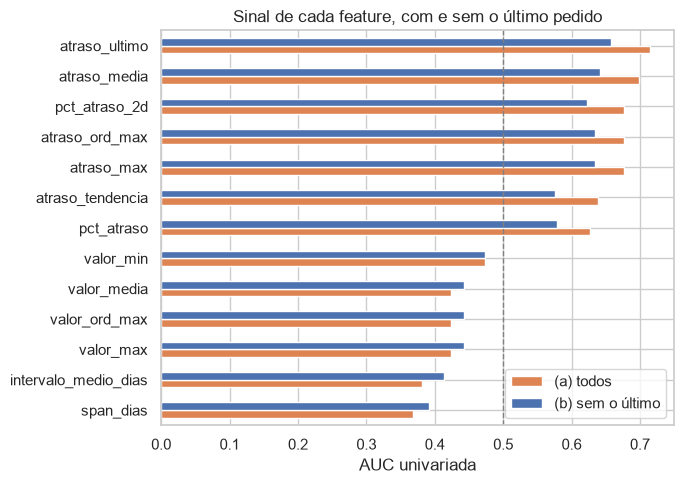

In [12]:
ax = auc[["(a) todos", "(b) sem o último"]].sort_values("(a) todos").plot.barh(figsize=(7, 5), color=["#DD8452", "#4C72B0"])
ax.axvline(0.5, color="gray", lw=1, ls="--")
ax.set_xlabel("AUC univariada"); ax.set_title("Sinal de cada feature, com e sem o último pedido")
plt.tight_layout(); plt.savefig(FIG / "kan7_auc_univariada.png", dpi=150); plt.show()

## 6. Redundância entre features

Correlação de Spearman na versão (a). Pares muito correlacionados carregam a mesma informação; a KAN-8 pode escolher um de cada grupo.

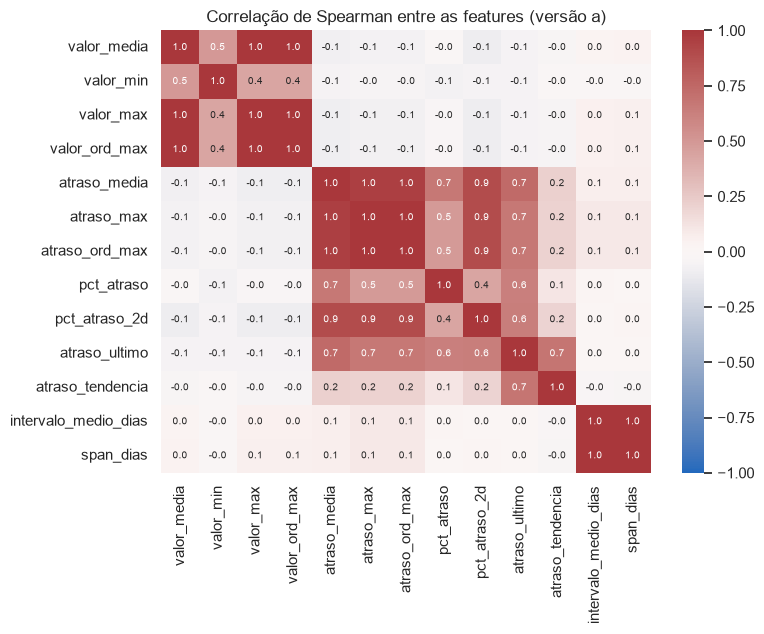

In [13]:
corr = todos.drop(columns="n_pedidos").corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlação de Spearman entre as features (versão a)")
plt.tight_layout(); plt.savefig(FIG / "kan7_correlacao.png", dpi=150); plt.show()

In [14]:
pares = corr.where(pd.DataFrame(
    [[i < j for j in range(len(corr))] for i in range(len(corr))], index=corr.index, columns=corr.columns)).stack()
pares[pares.abs() >= 0.8].sort_values(ascending=False).round(2)

valor_max             valor_ord_max     1.00
atraso_max            atraso_ord_max    1.00
intervalo_medio_dias  span_dias         1.00
valor_media           valor_max         0.99
                      valor_ord_max     0.99
atraso_media          atraso_max        0.96
                      atraso_ord_max    0.96
atraso_max            pct_atraso_2d     0.89
atraso_ord_max        pct_atraso_2d     0.89
atraso_media          pct_atraso_2d     0.89
dtype: float64

## 7. Salvar

In [15]:
dados.DIR_PROCESSED.mkdir(parents=True, exist_ok=True)
todos.to_csv(dados.DIR_PROCESSED / "features_comportamentais_todos.csv")
sem_ultimo.to_csv(dados.DIR_PROCESSED / "features_comportamentais_sem_ultimo.csv")
print("salvo em data/processed/ (não versionado)")

# Uso na KAN-8:
#   feats = fc.agregar_pedidos(fc.converter_pedidos(pedidos), excluir_ultimo=...)
#   base = fc.juntar_clientes(clientes, feats)  # left join + tem_pedidos
base = fc.juntar_clientes(clientes, todos)
print("base juntada:", base.shape, "| tem_pedidos:", base["tem_pedidos"].sum())

salvo em data/processed/ (não versionado)
base juntada: (3000, 34) | tem_pedidos: 664


## 8. Conclusões

**Entrega:** `src/features_comportamentais.py` gera 14 features por cliente (dicionário na seção 4), em duas versões: (a) com todos os pedidos e (b) sem o último. Só 664 dos 3.000 clientes (22%) têm pedidos; `juntar_clientes` faz o left join e cria `tem_pedidos`.

**O que os dados permitem:**
- Quase todo cliente tem exatamente 3 pedidos, então volume de compras não é observável e `n_pedidos` não deve entrar no modelo.
- O sinal está no **atraso**: AUC univariada de 0,63 a 0,71 nas features de atraso, contra 0,42 a 0,47 nas de valor (valor maior → um pouco menos inadimplência).
- `intervalo_medio_dias` e `span_dias` têm AUC de 0,37 a 0,38 (intervalos longos → menos inadimplência). Parte disso pode ser efeito de época, como na seção 2.

**Vazamento:**
- Atraso acima de 2 dias pesa mais quanto mais recente o pedido: a taxa de inadimplência passa de 28,9% (antepenúltimo) para 38,3% (último) entre quem atrasou, e cai de 16,7% para 13,6% entre quem não atrasou.
- Sem o último pedido, as features de atraso perdem de 0,04 a 0,06 de AUC, mas continuam com sinal (0,58 a 0,66). Ou seja, o histórico ajuda mesmo na versão conservadora.
- A taxa varia de 6,7% a 30,2% conforme o trimestre do último pedido, por isso não criamos recência absoluta.

**Recomendações para a KAN-8:**
1. Treinar com as duas versões e reportar as duas AUCs; usar a (b) como resultado principal enquanto a Praso não disser quando a inadimplência foi observada.
2. Escolher uma feature de cada grupo redundante (Spearman ≥ 0,8): `valor_max`/`valor_ord_max`/`valor_media`, `atraso_max`/`atraso_ord_max`/`atraso_media`/`pct_atraso_2d`, `intervalo_medio_dias`/`span_dias`.
3. Imputar `atraso_tendencia` e `intervalo_medio_dias` (nulos com 1 pedido) dentro do `Pipeline`.
4. O filtro "clientes que compraram nos últimos 30 dias" depende de uma data de referência que não temos. A alternativa é modelar todos os clientes com pedidos.

**Pergunta em aberto (Praso/professor):** existe uma data de referência? O último pedido é anterior ao evento de inadimplência?
